In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# Loading the csv in a dataframe
df: pd.DataFrame = pd.read_csv("/Users/laurent/Documents/Charles/DALAS-project/data/raw/consumer.csv", delimiter=",")

/var/folders/_y/l96v6slj3sxbrl6c50303fx80000gn/T/ipykernel_14916/1378344809.py:5: DtypeWarning: Columns (8: Observation flag) have mixed types. Specify dtype option on import or set low_memory=False.
  df: pd.DataFrame = pd.read_csv("/Users/laurent/Documents/Charles/DALAS-project/data/raw/consumer.csv", delimiter=",")


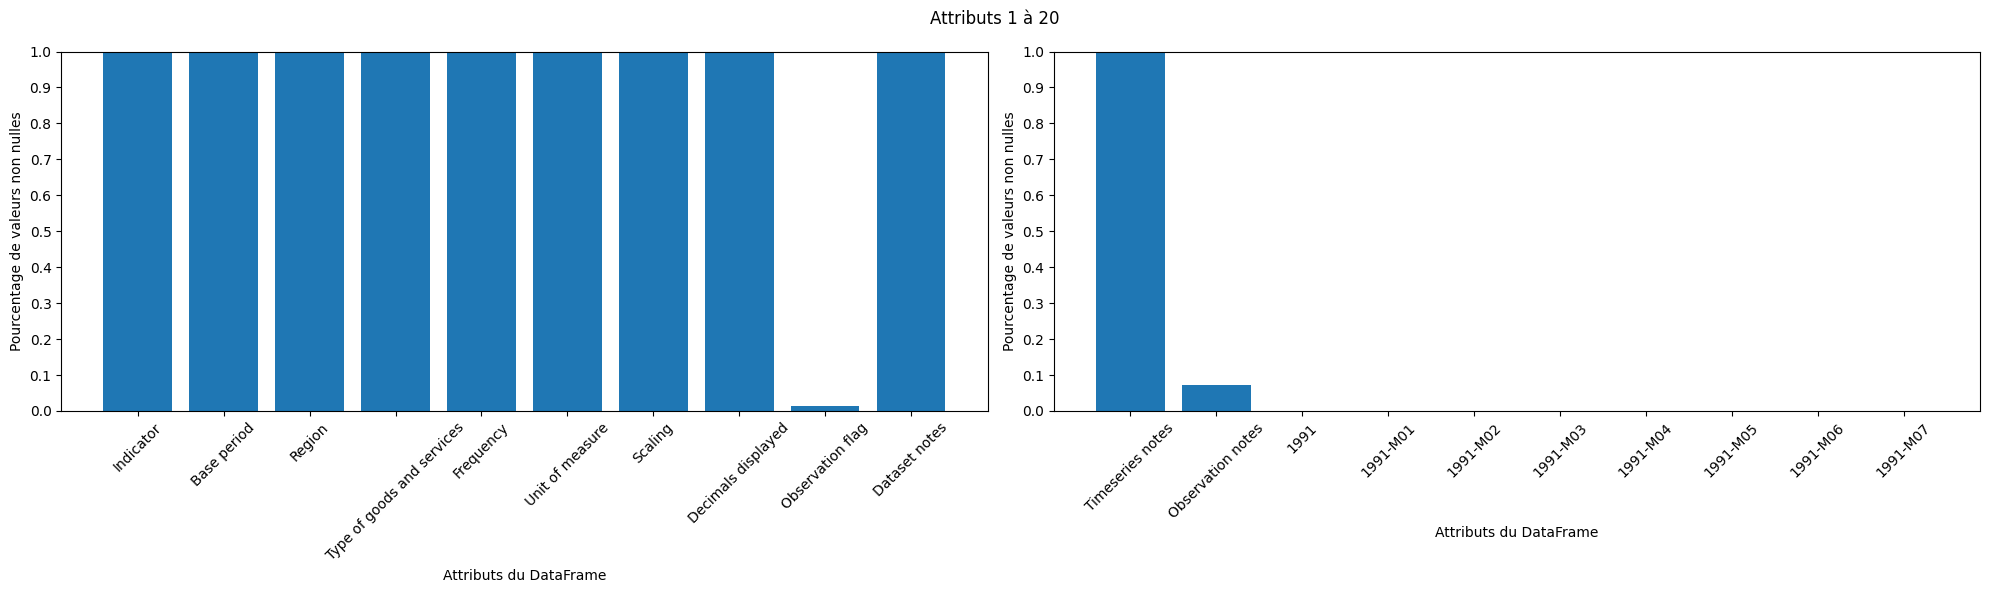

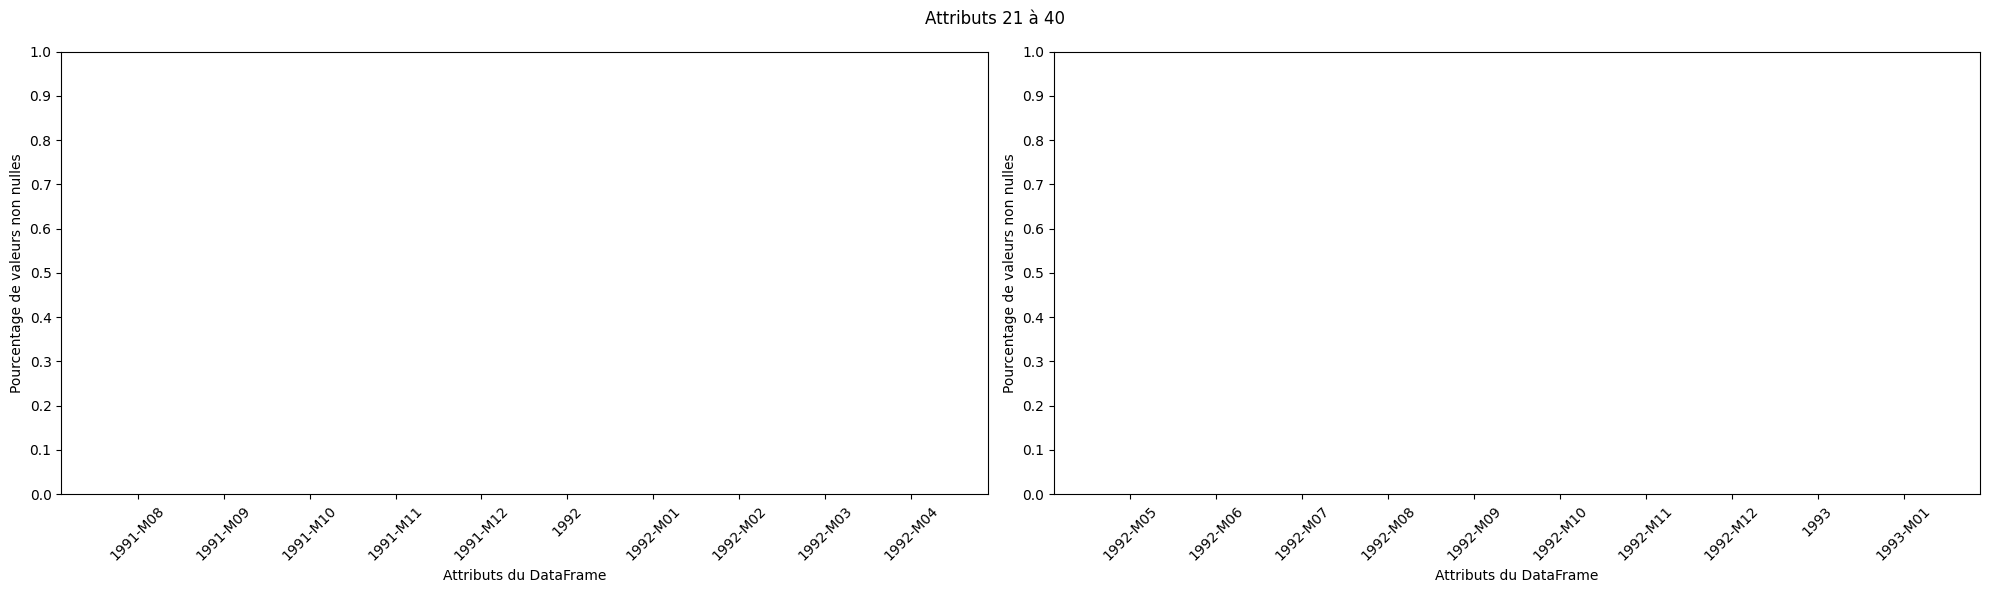

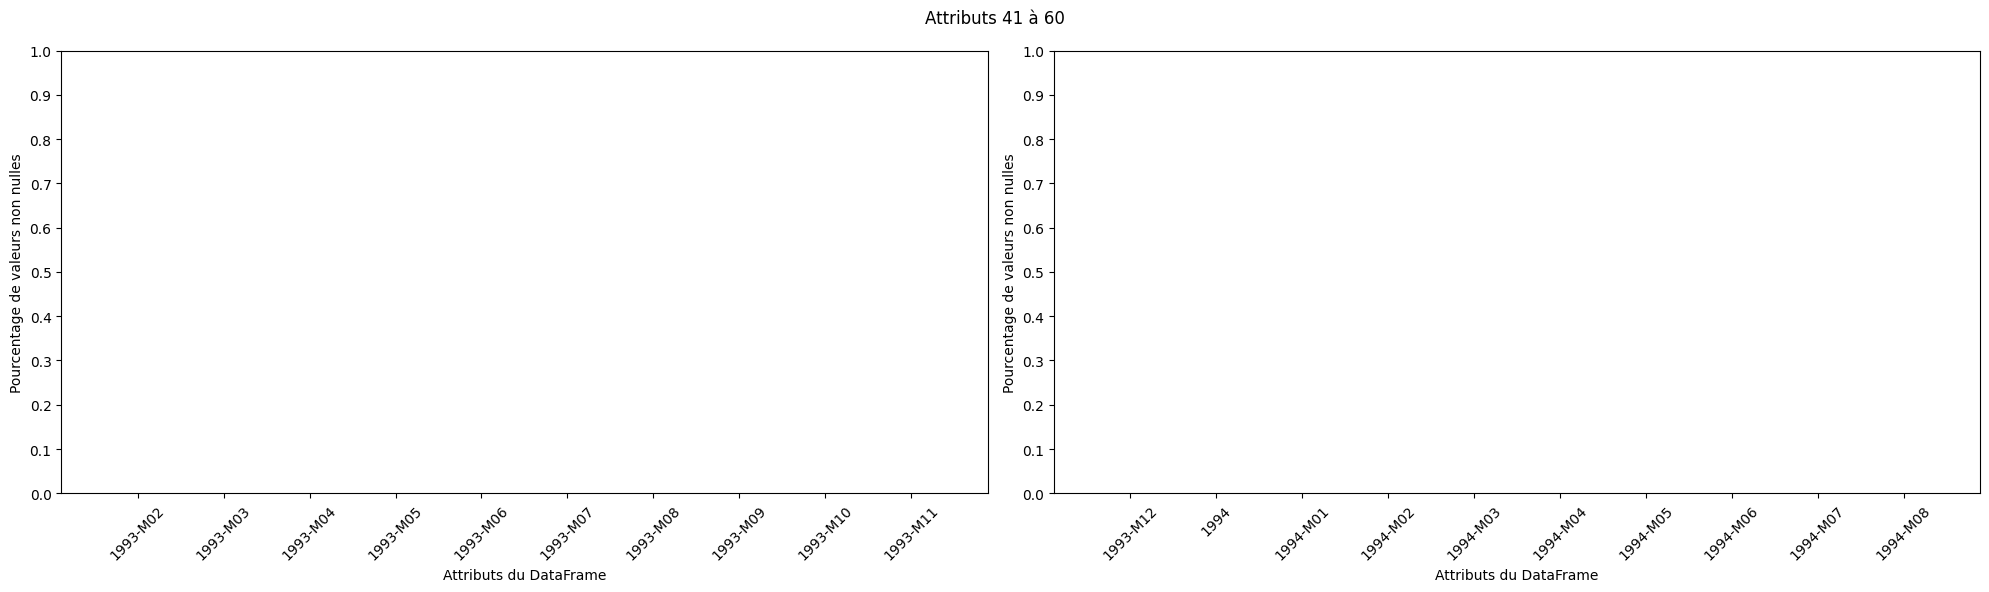

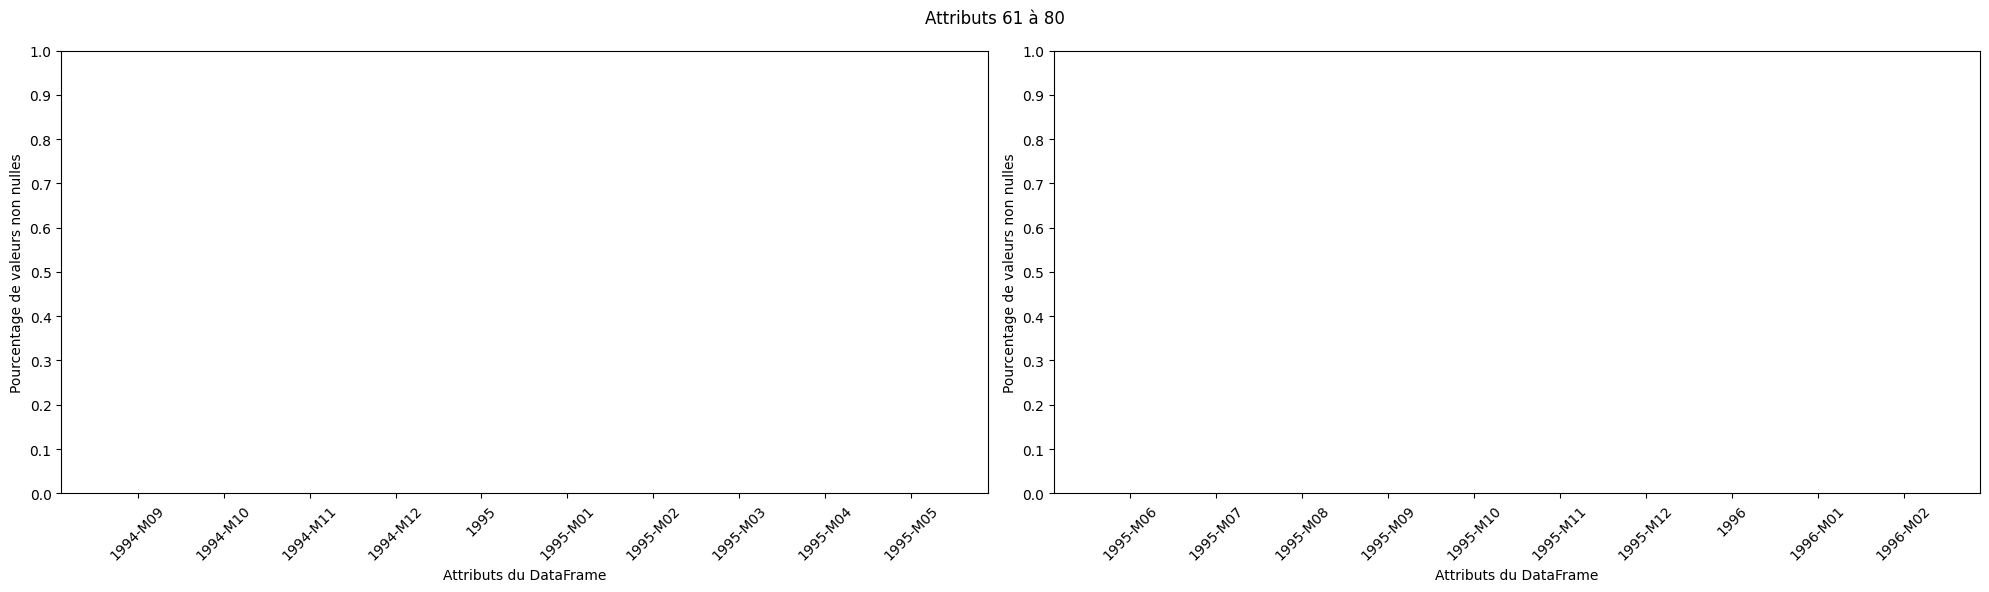

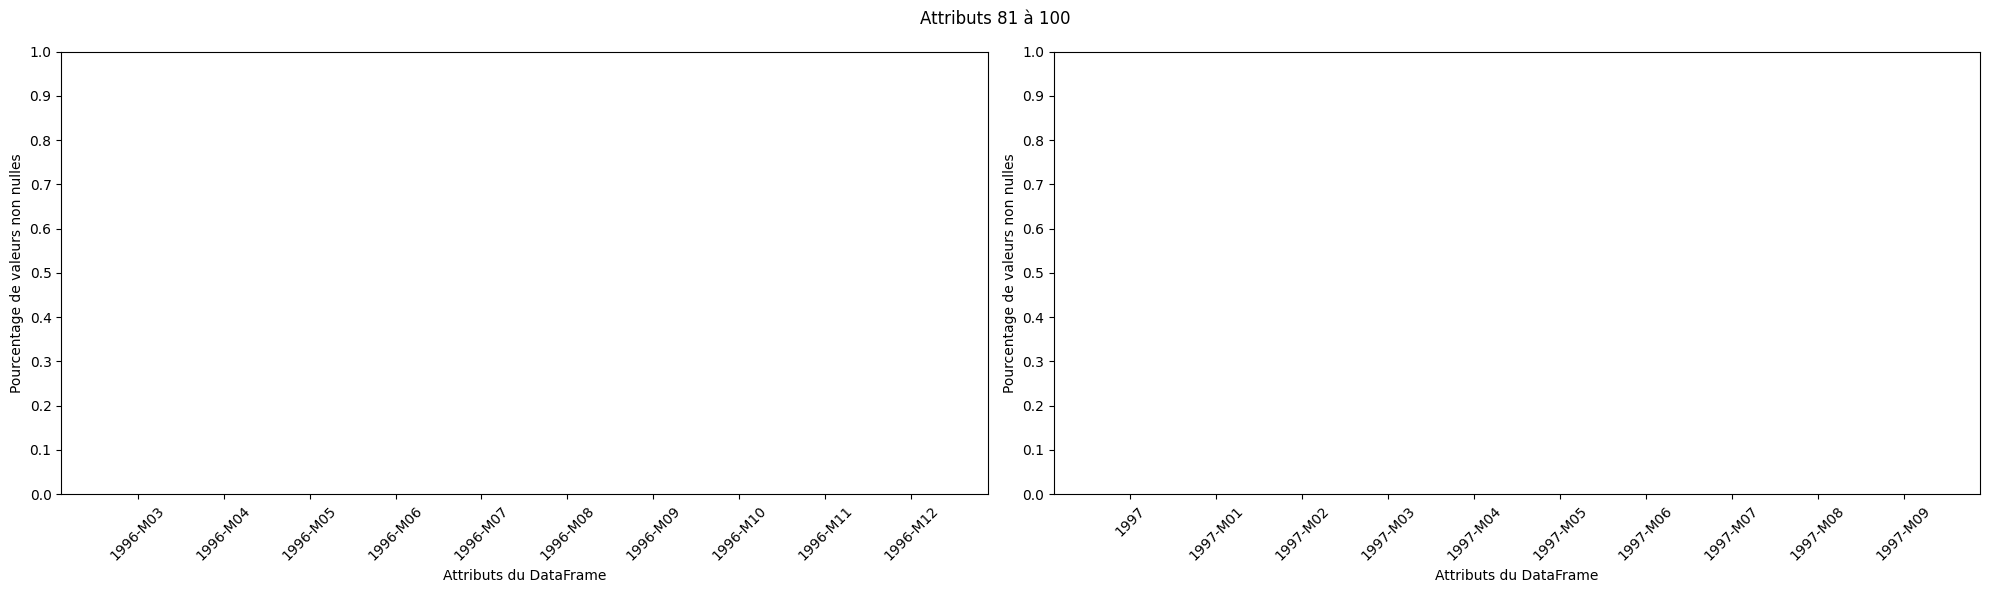

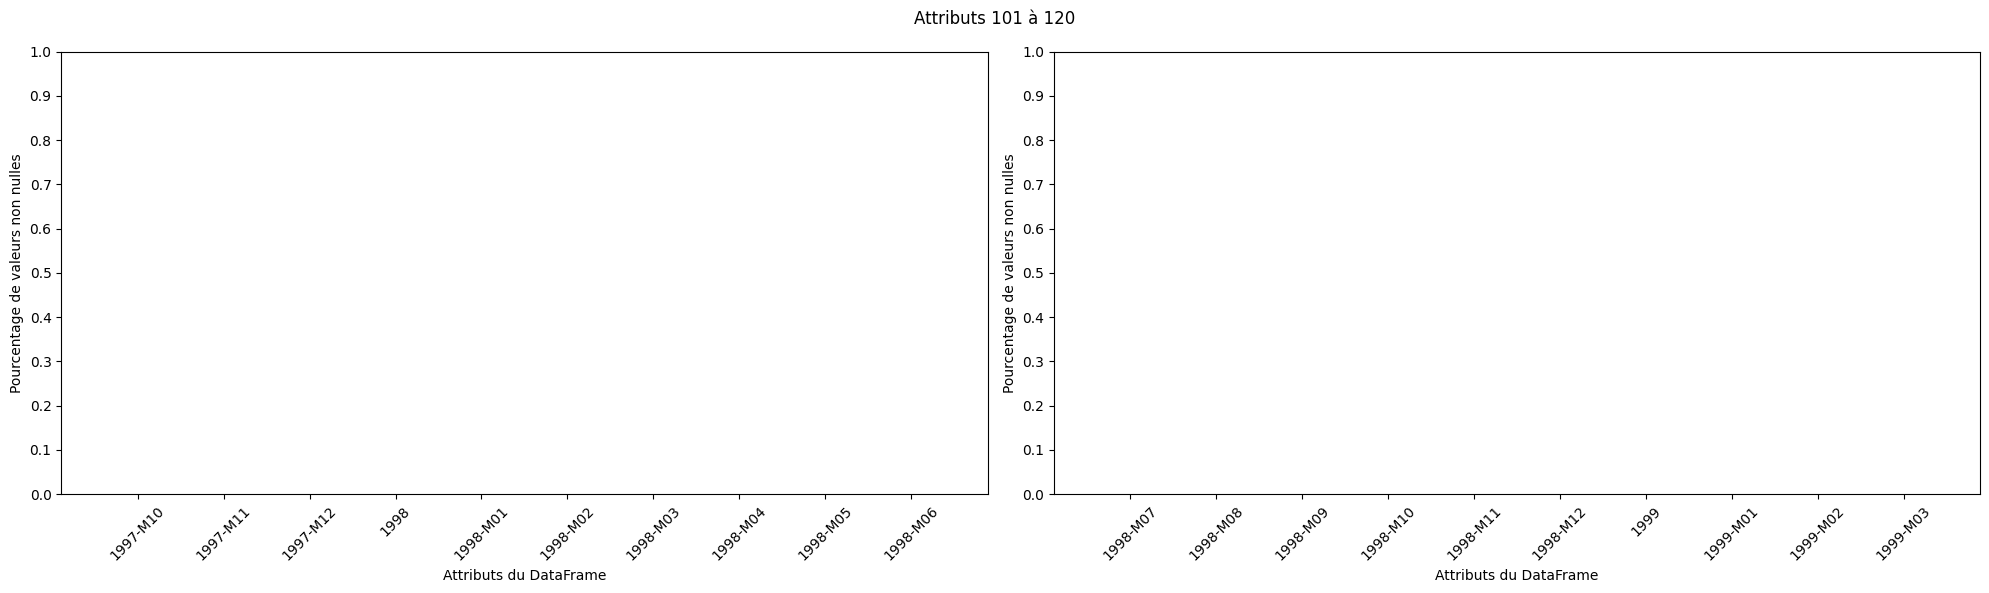

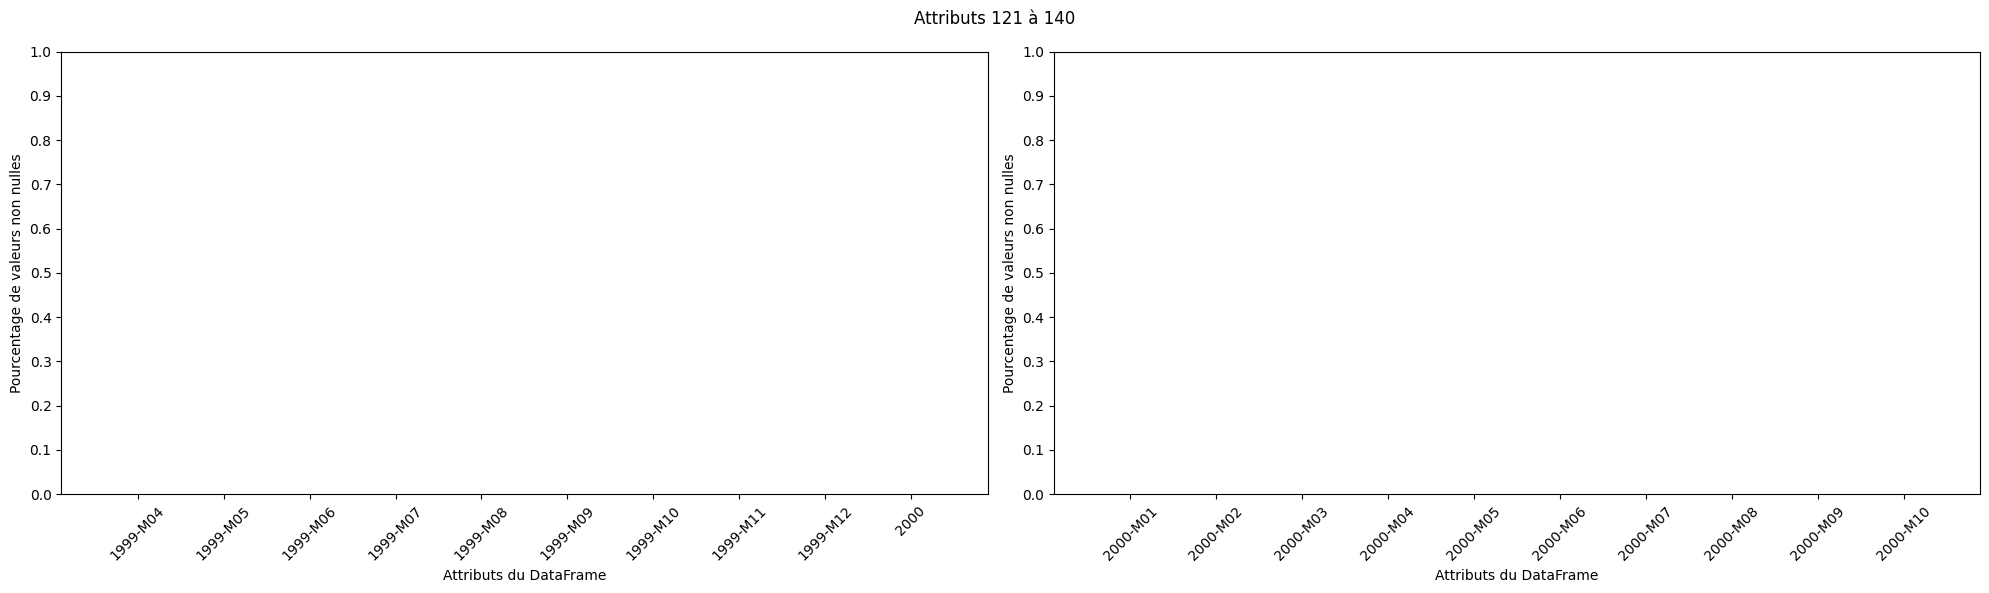

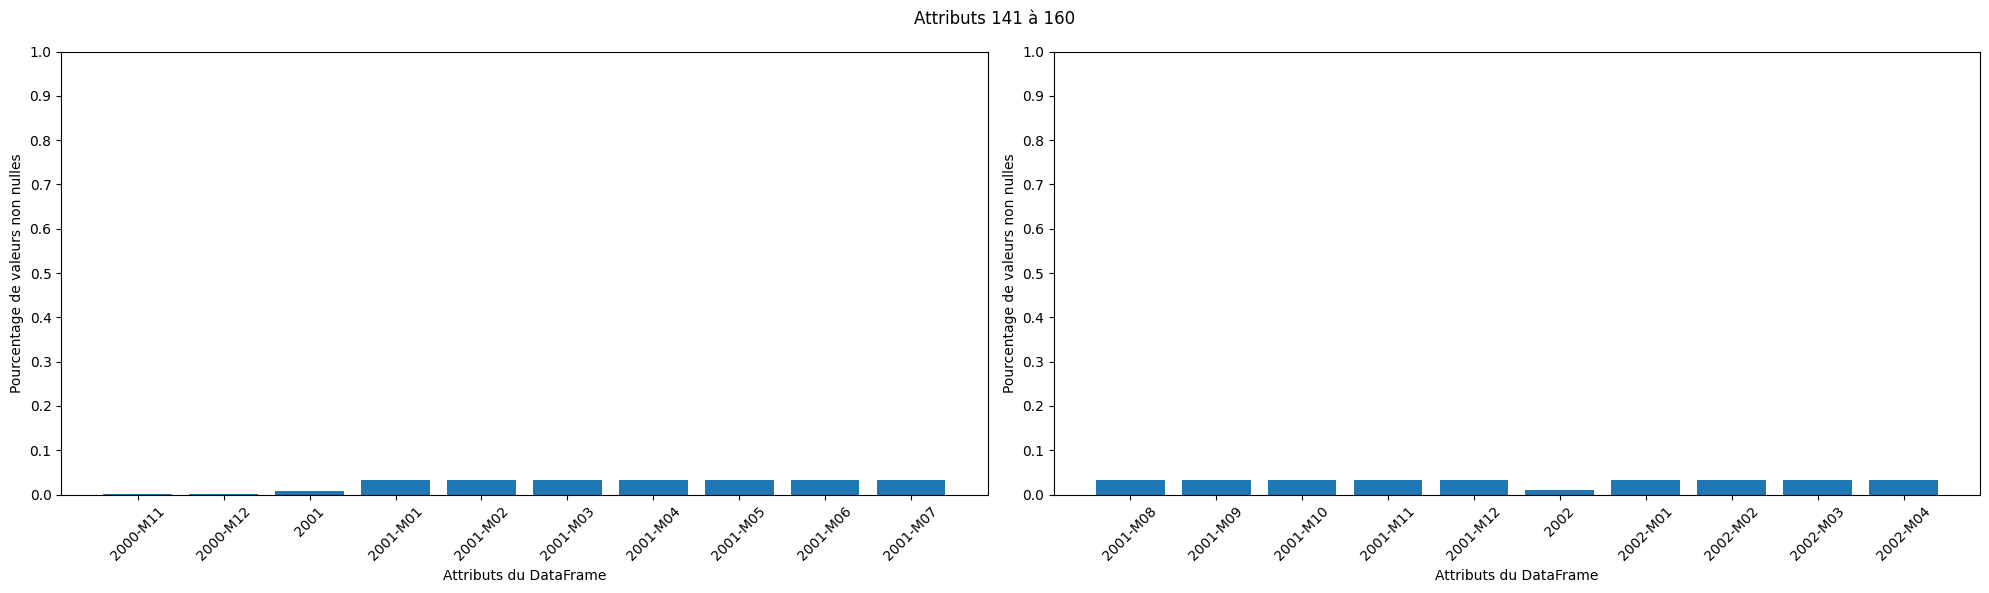

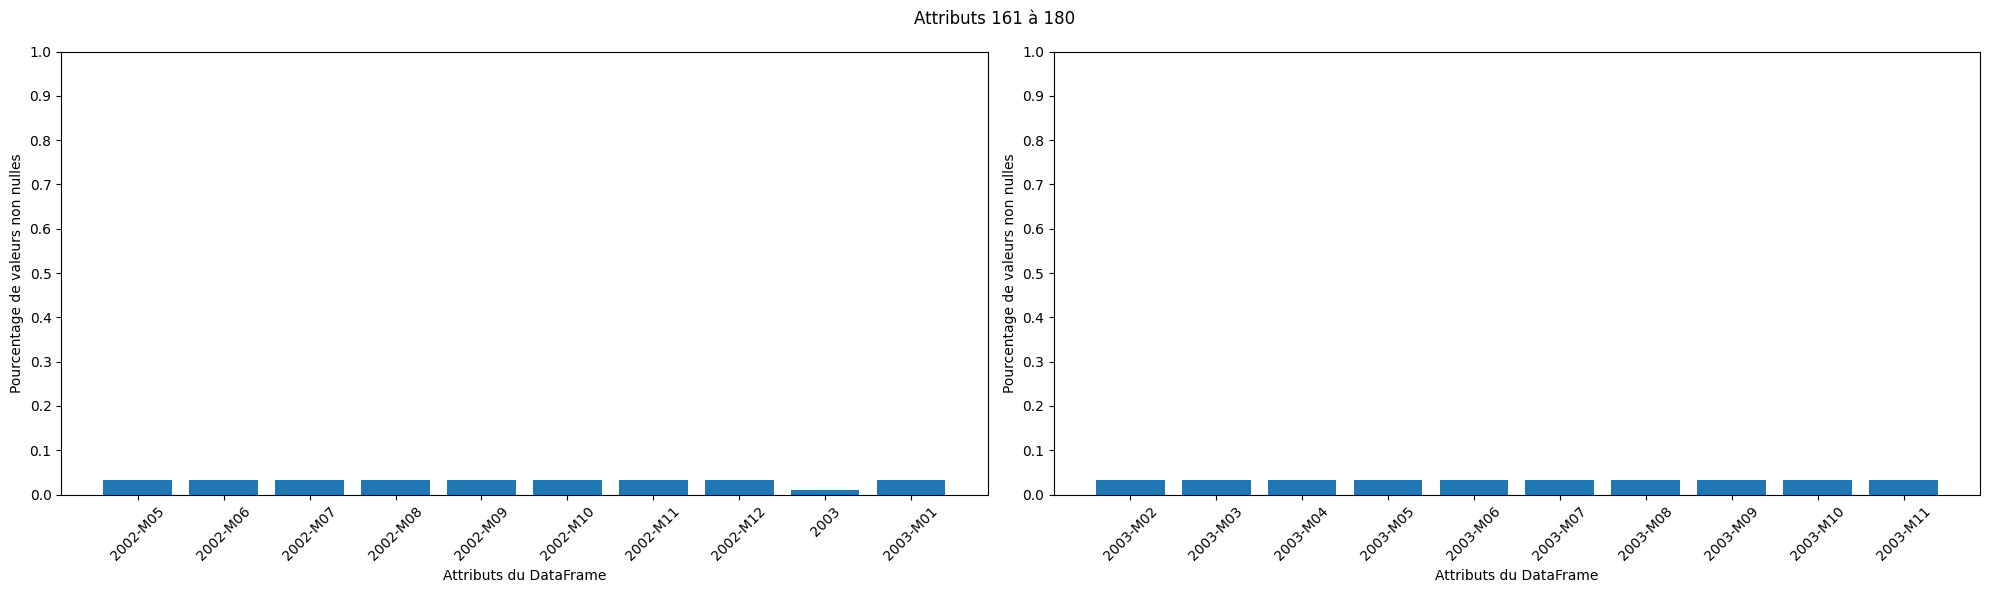

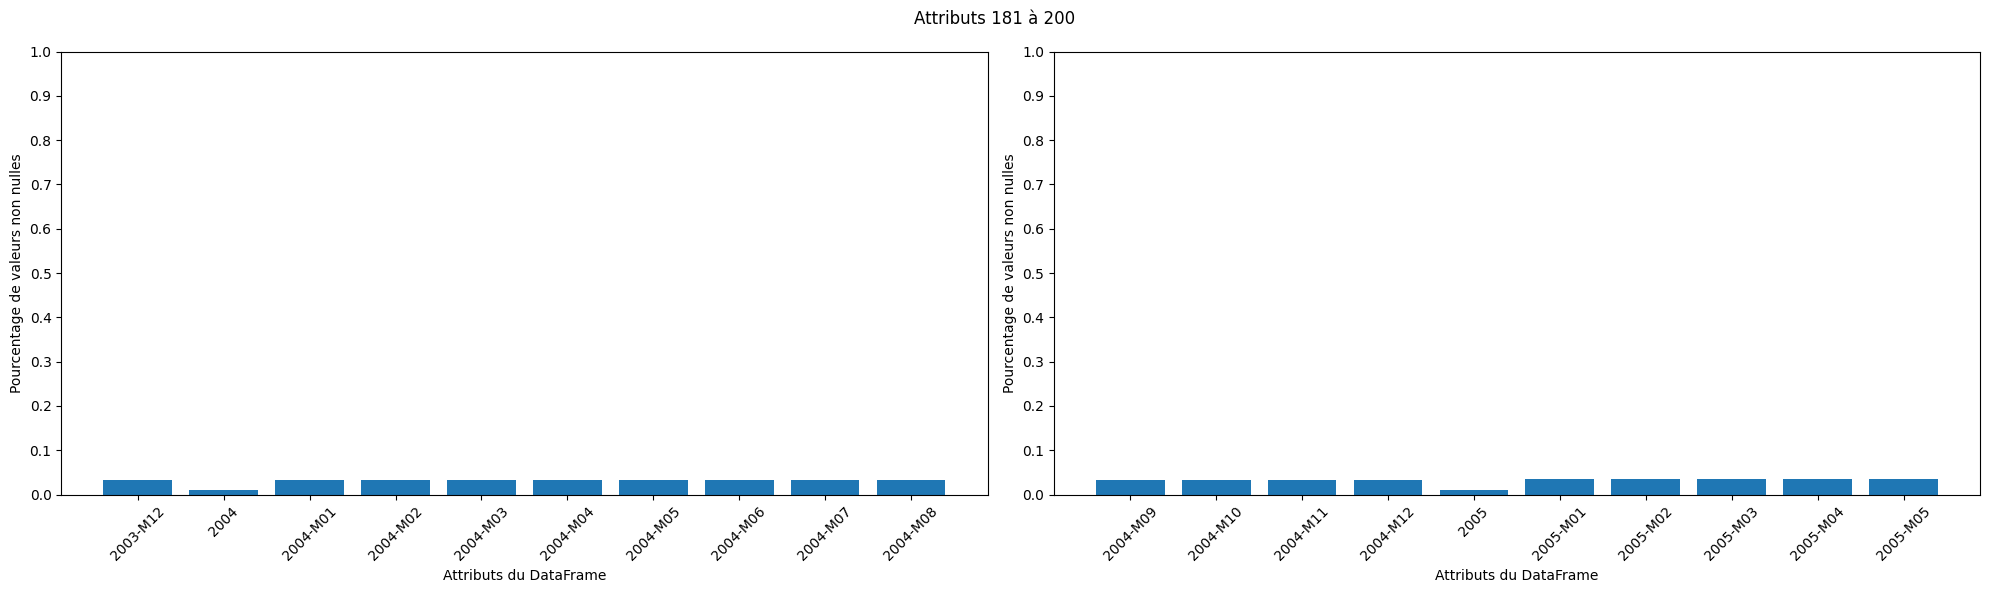

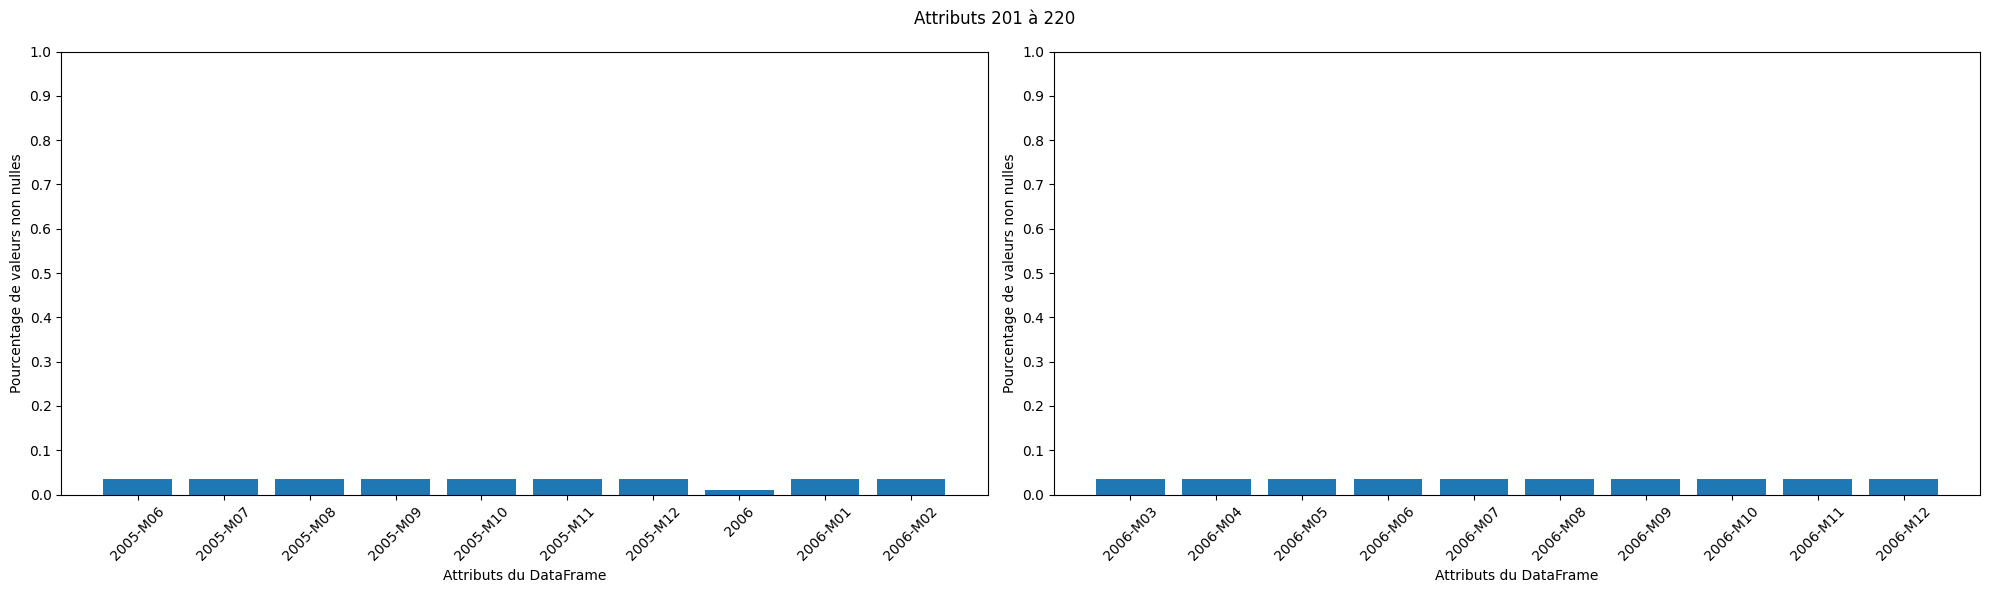

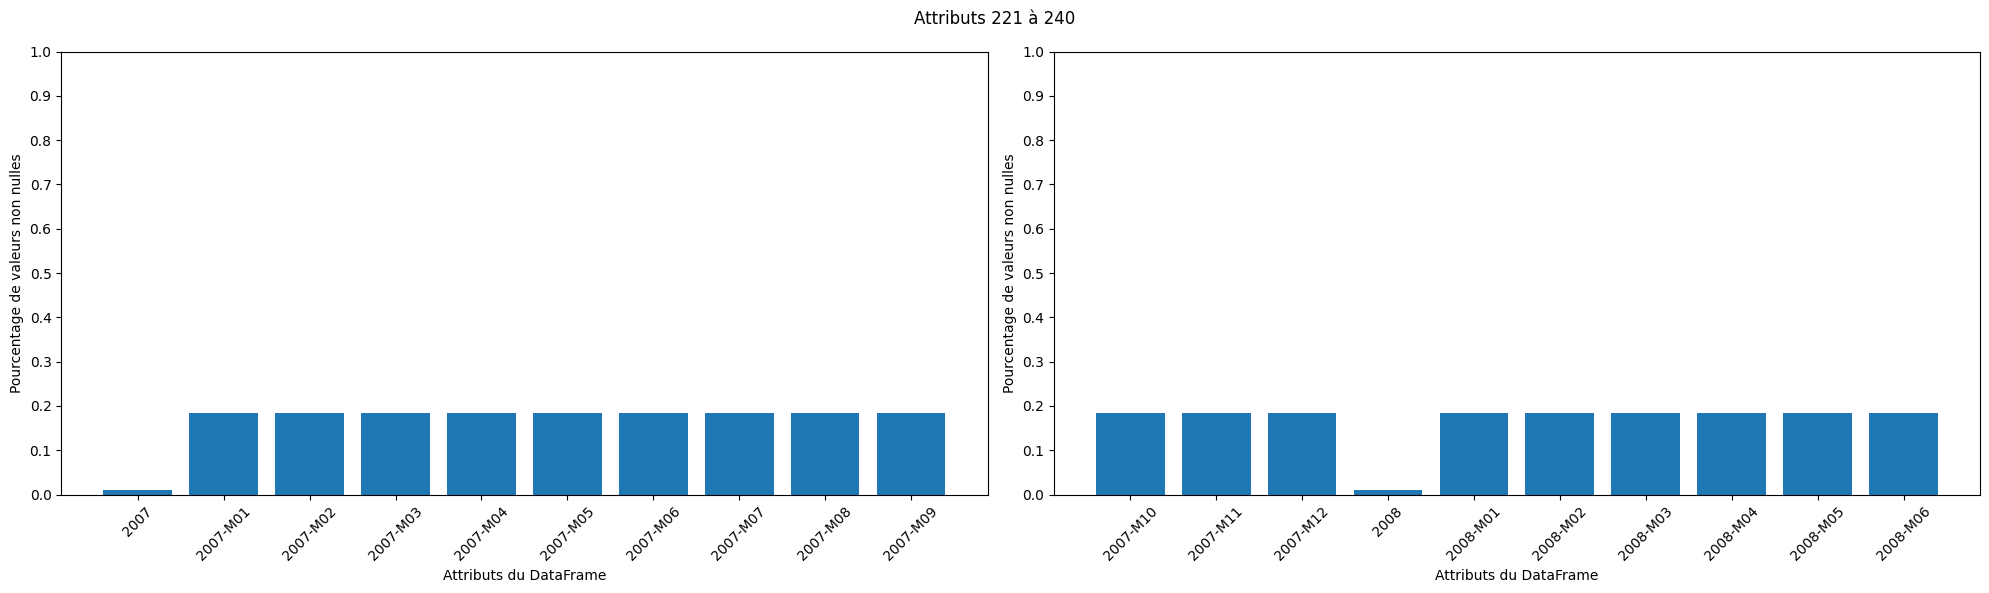

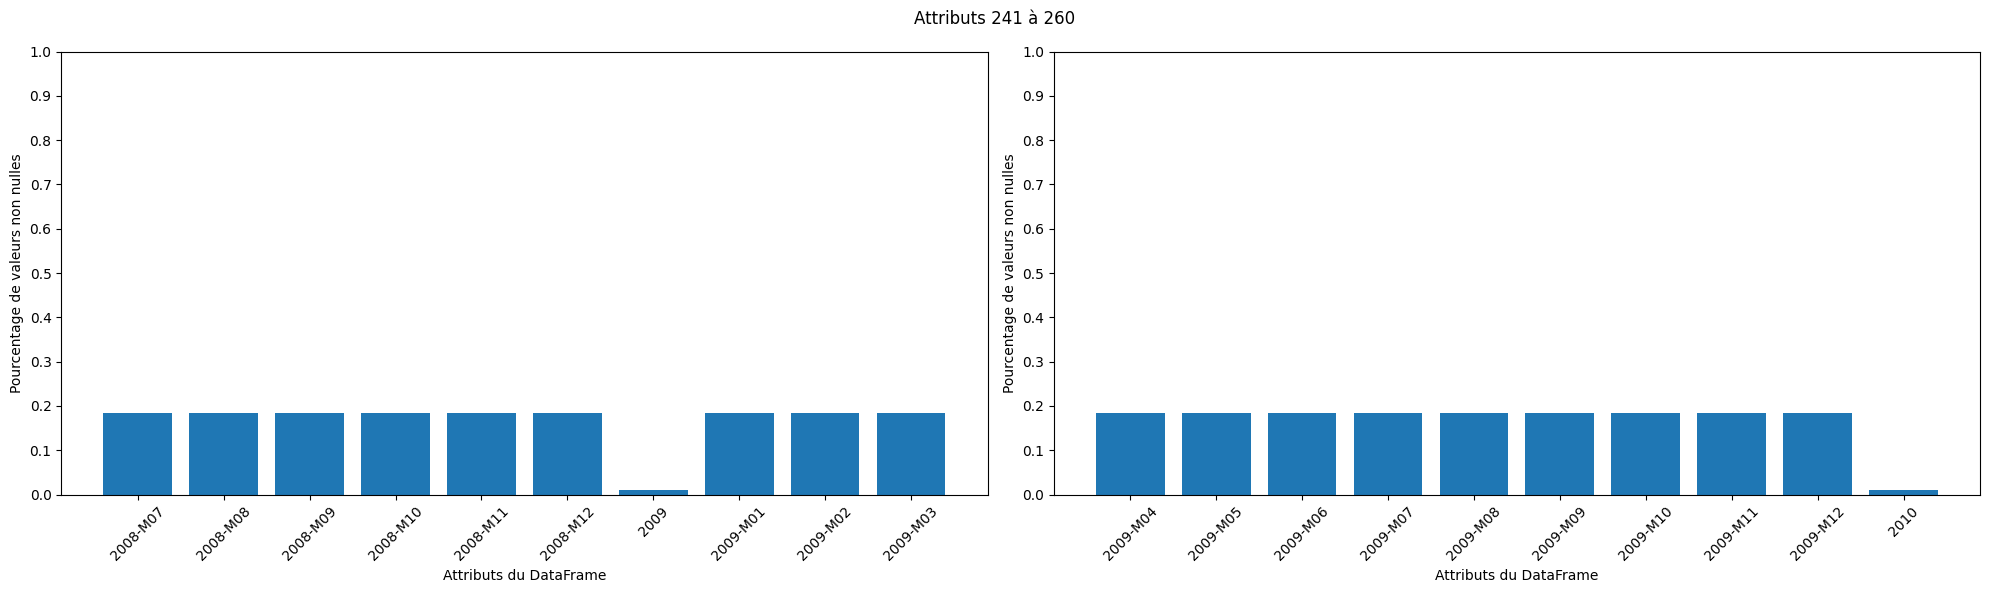

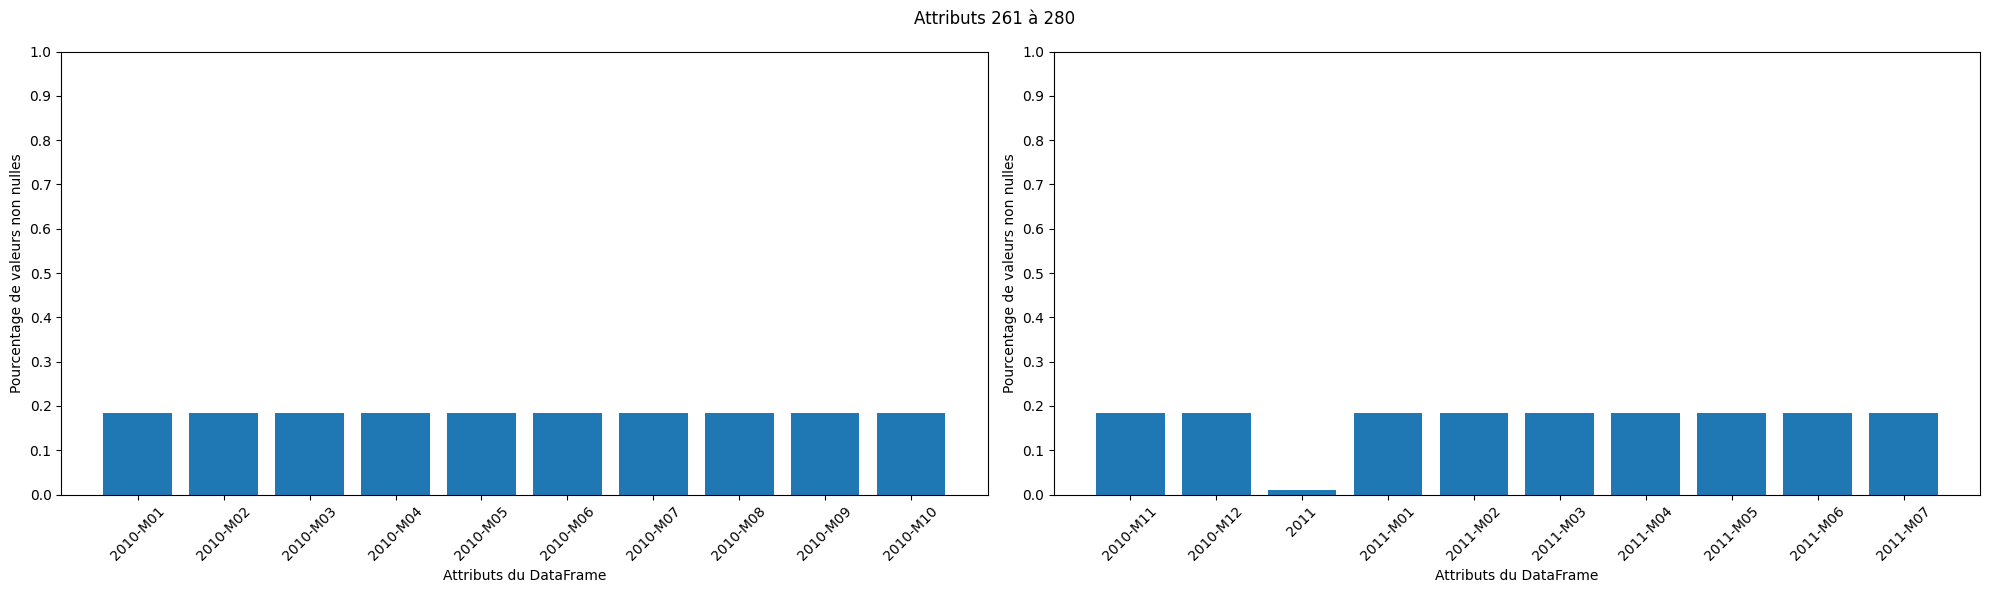

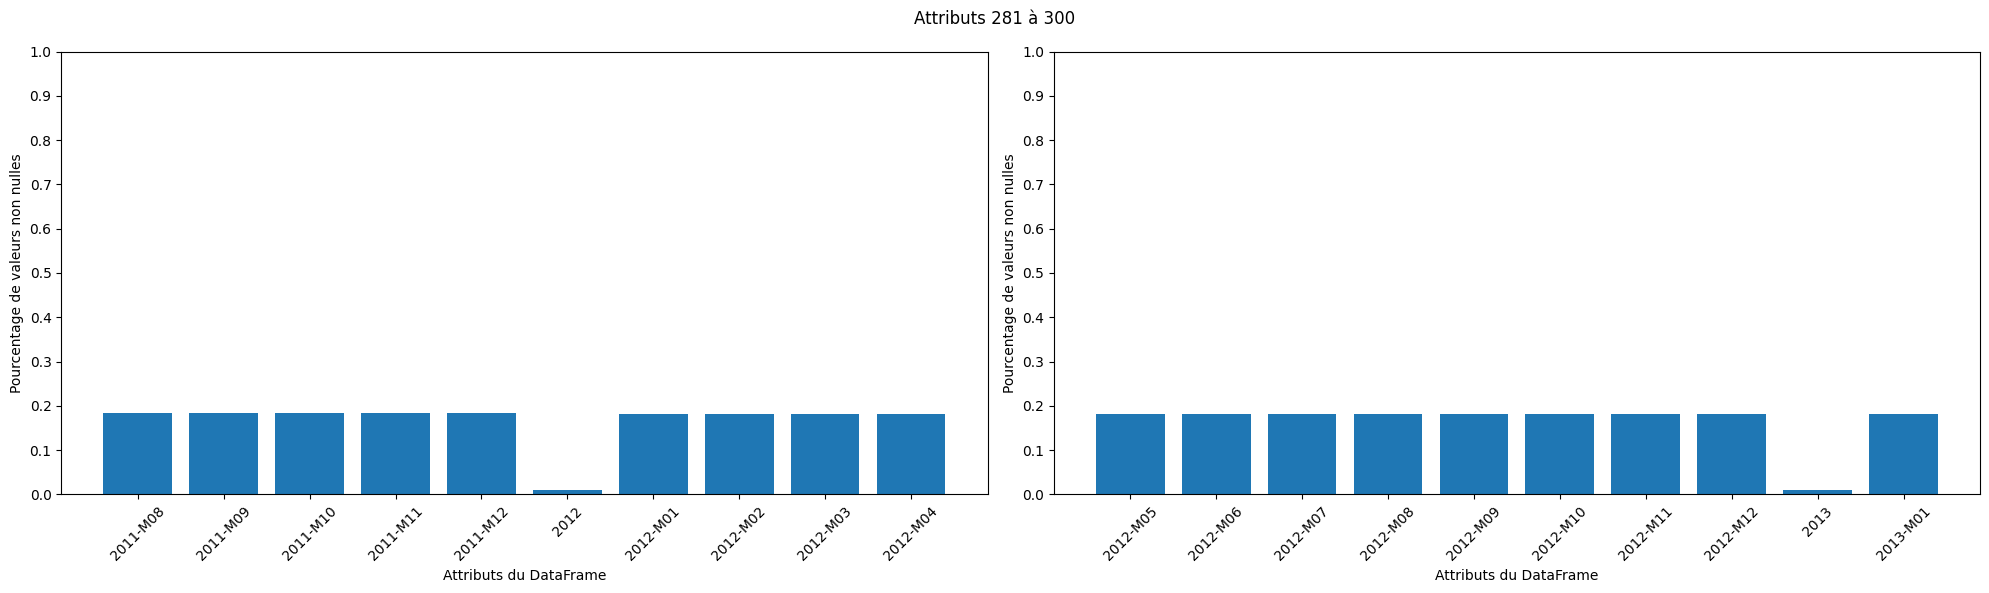

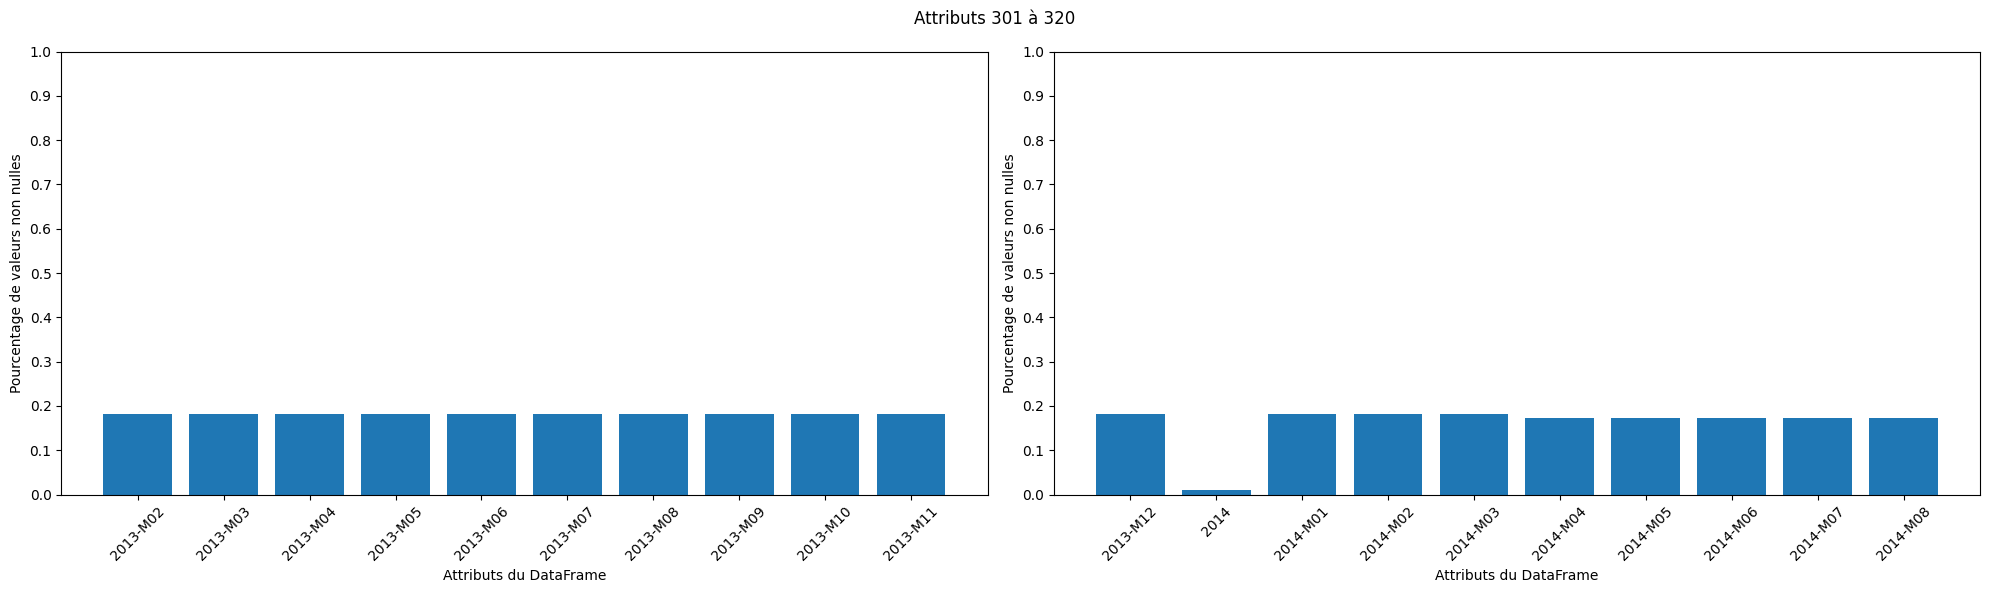

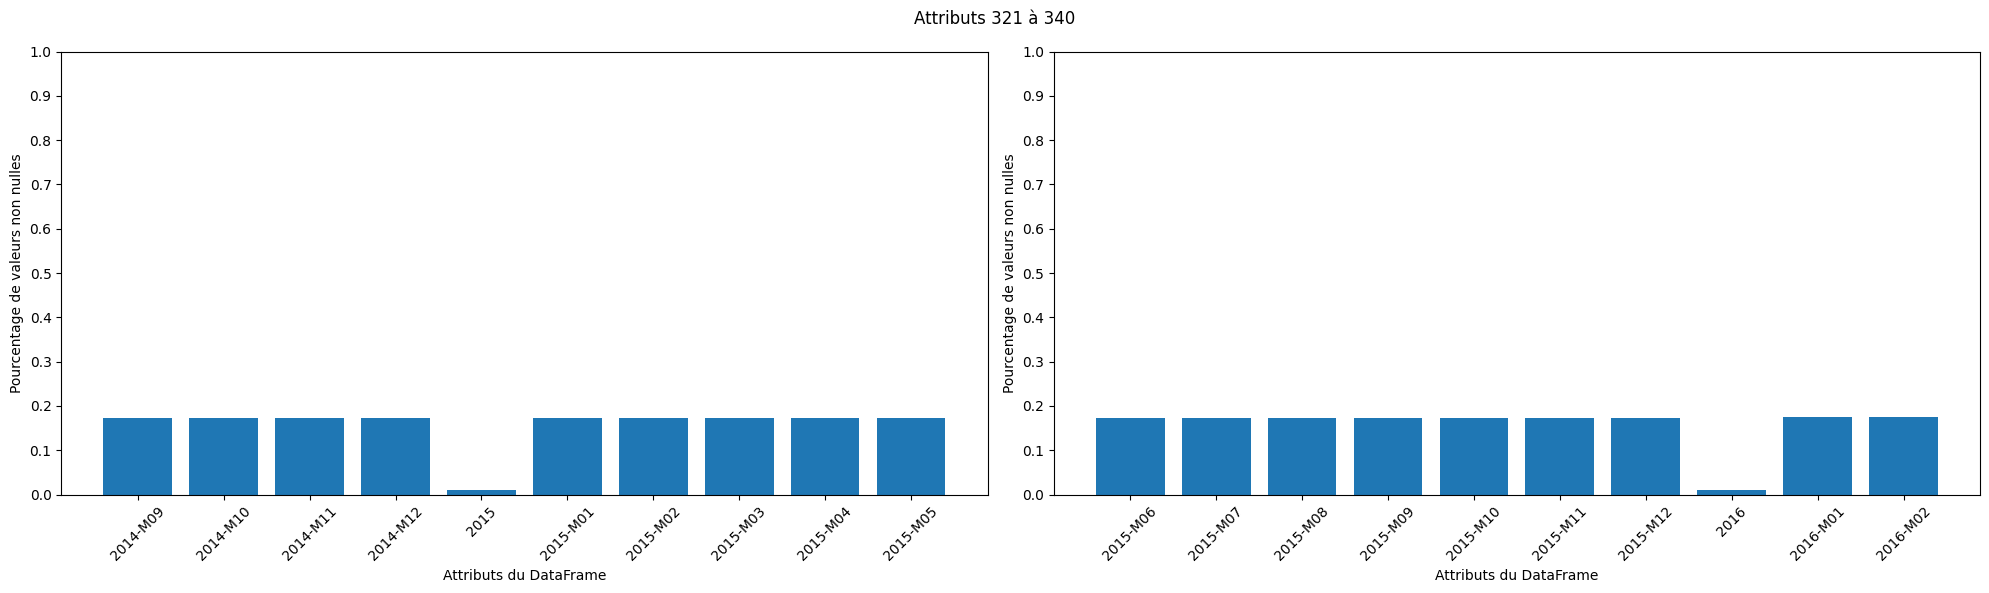

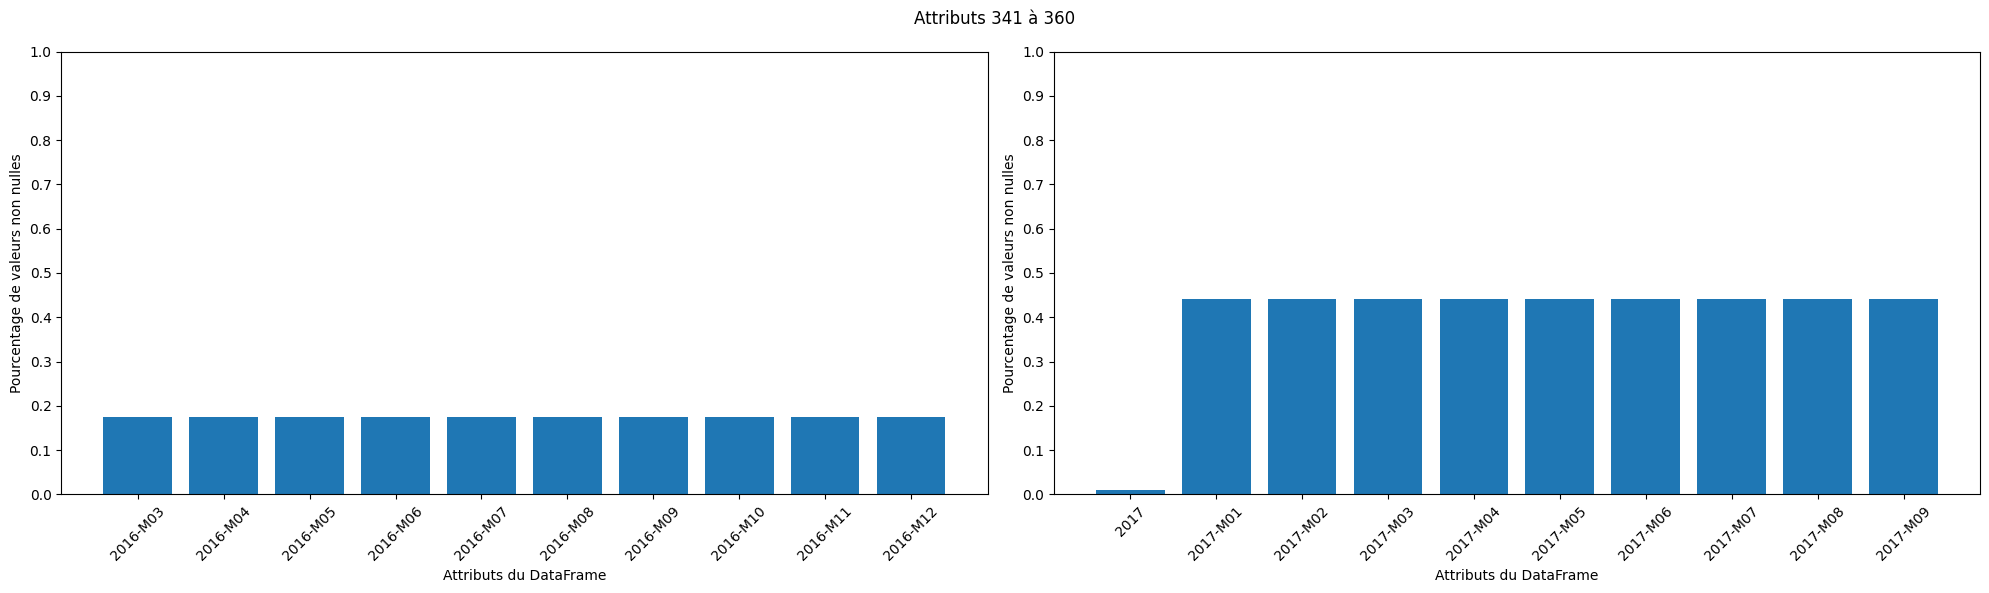

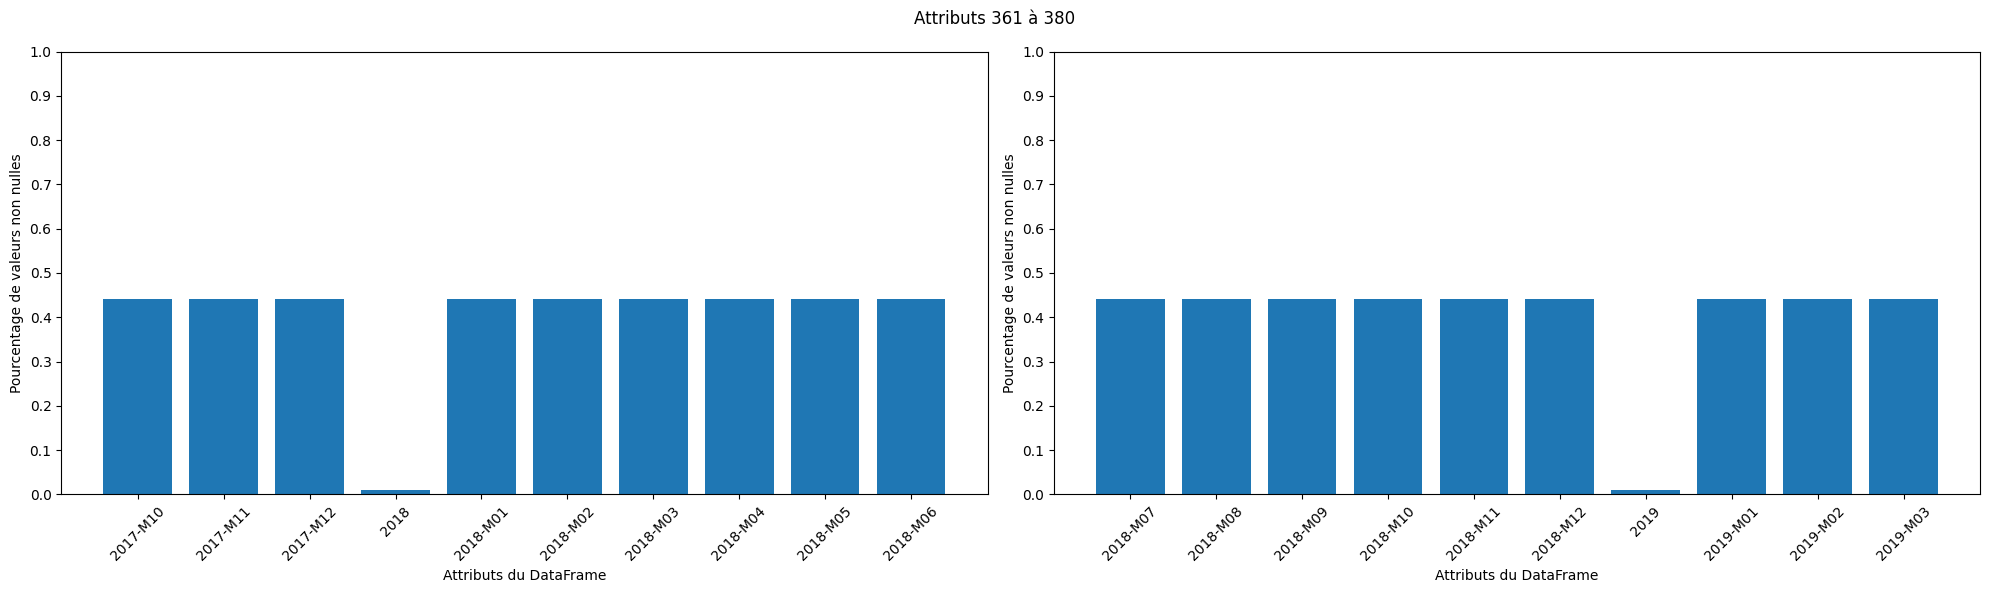

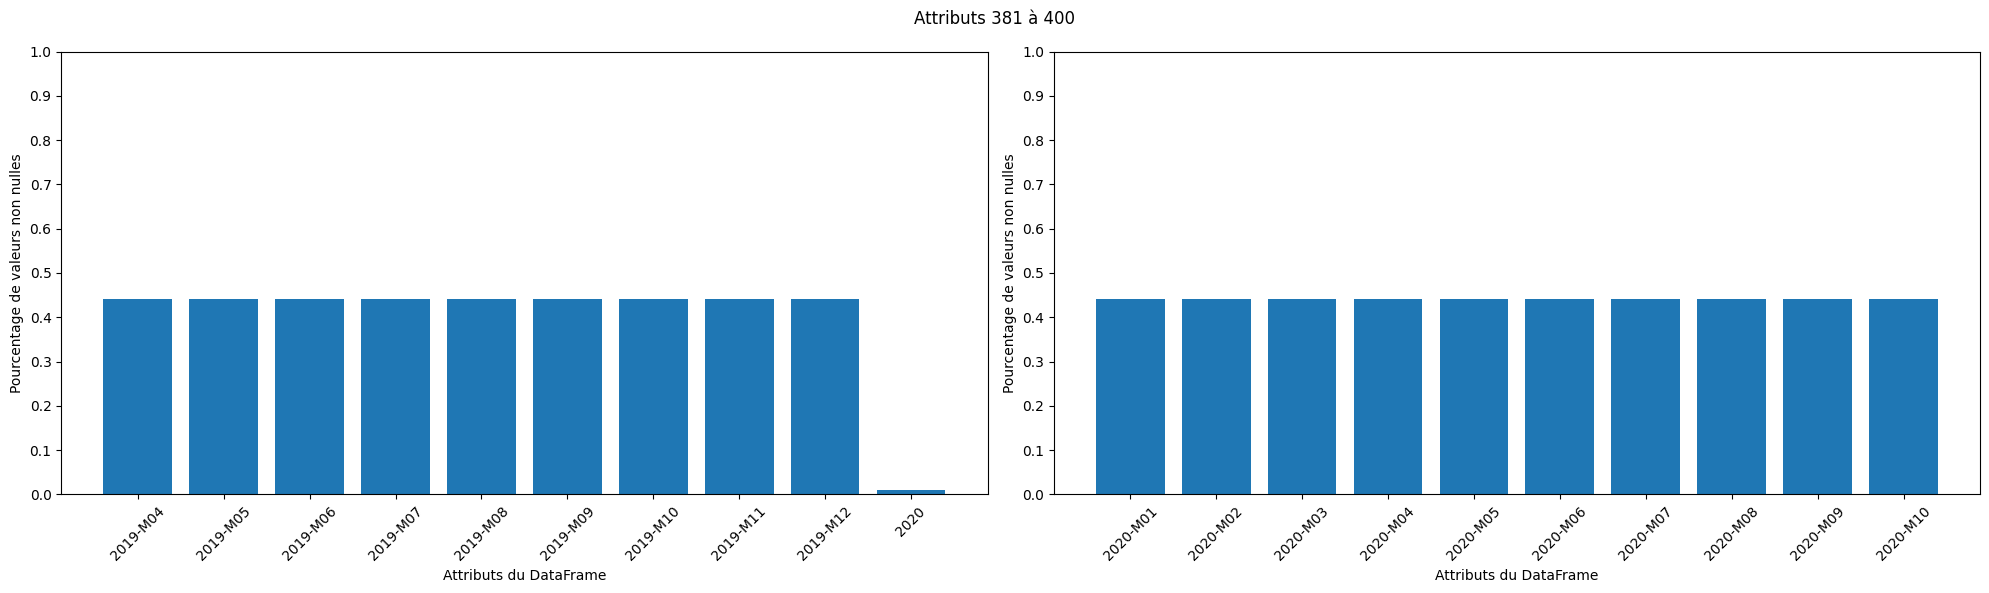

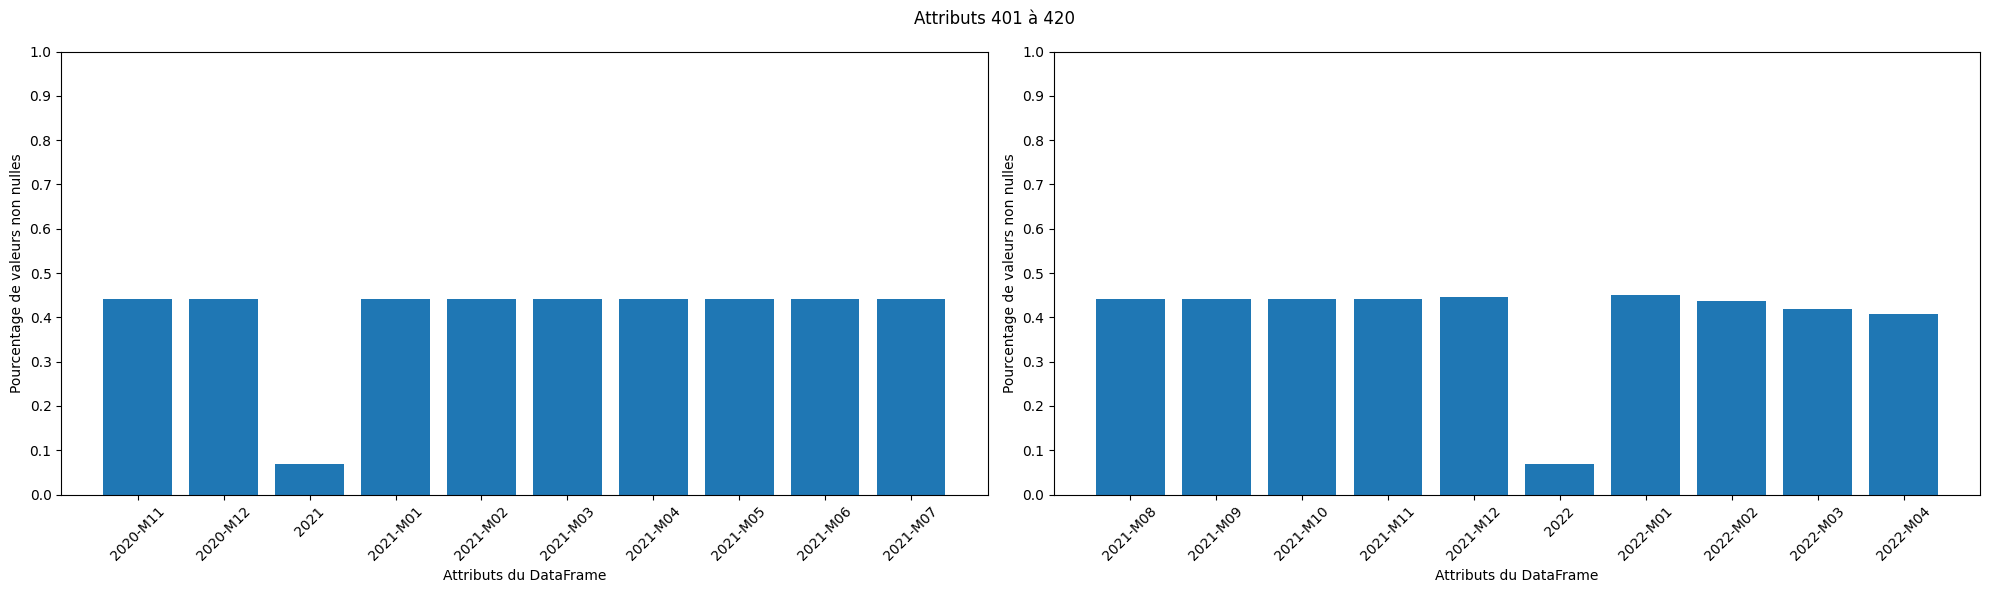

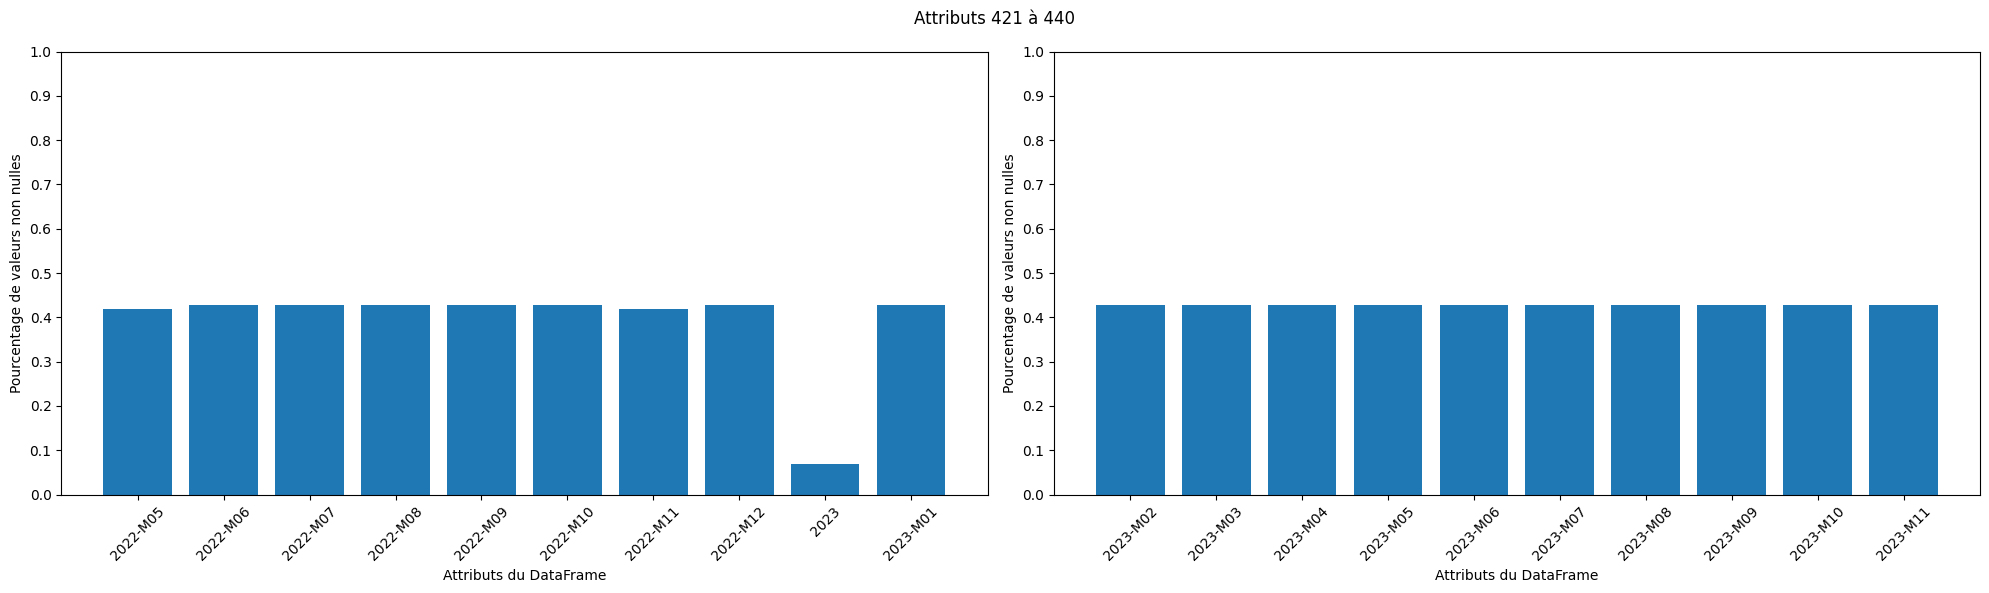

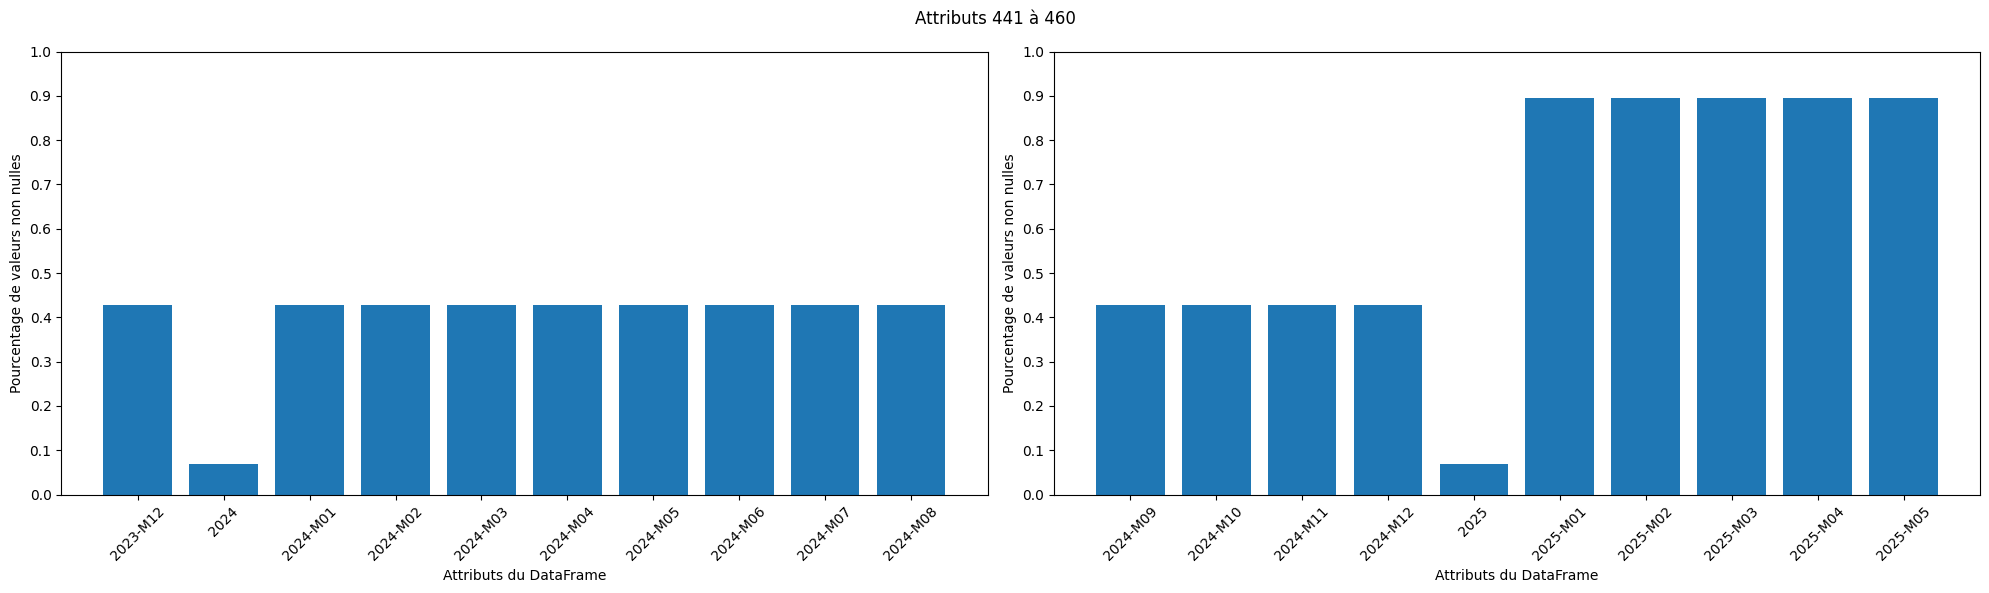

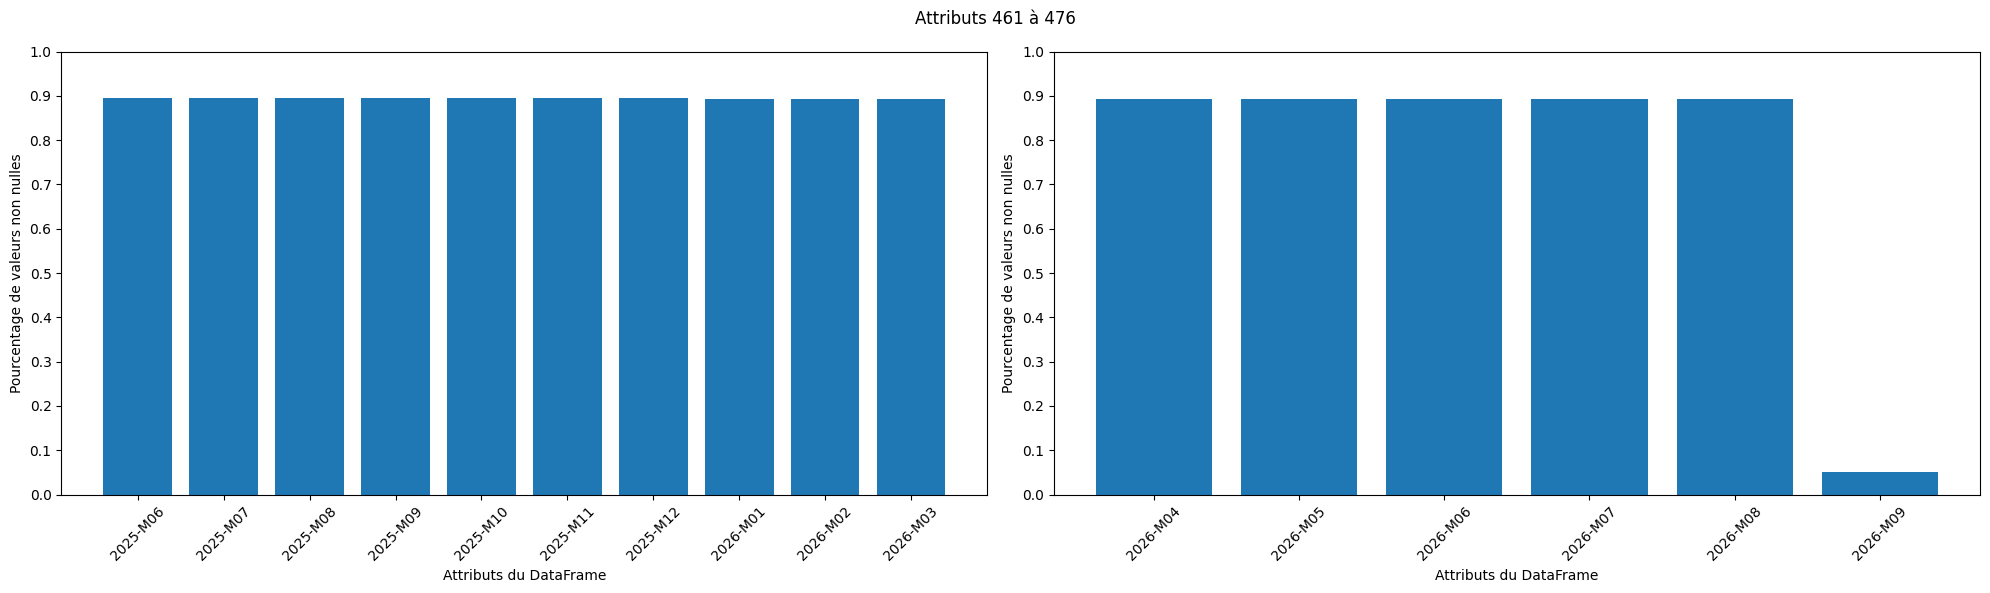

In [ ]:
# Cette section se charge d'afficher le pourcentage de valeurs non nulles pour chaque attribut du dataframe, afin de déterminer lesquels seront judicieux à analyser

nb_lines: int = len(df)
columns = df.columns
nb_columns = len(columns)

array = []

for i in range(nb_columns):
    array.append([str(columns[i]), df[columns[i]].count() / nb_lines])

batch_size = 20

for start in range(0, nb_columns, batch_size):
    batch = array[start:start + batch_size]

    fig, axes = plt.subplots(1, 2, figsize=(20, 6))

    for j, ax in enumerate(axes):
        sub_batch = batch[j * 10:(j + 1) * 10]

        ax.bar([x[0] for x in sub_batch],[x[1] for x in sub_batch])

        ax.set_ylim(0, 1)
        ax.set_yticks(np.arange(0, 1.1, 0.1))
        ax.tick_params(axis="x", labelrotation=45)
        ax.set_ylabel("Pourcentage de valeurs non nulles")
        ax.set_xlabel("Attributs du DataFrame")

    fig.suptitle(f"Attributs {start + 1} à {start + len(batch)}")

    plt.tight_layout()
    plt.show()

    # On se rend compte qu'en affichant les graphiques, un grand nombre d'attributs ont un pourcentage de valeurs non nulles qui est
    # bien en dessous des 80 %, ce qui ne nous permet pas de pouvoir exploiter pleinement ce dataset.